# 🧪 ML-Based Drug-Target Binding Affinity Prediction (Kinase Inhibitors)

**Course project: Artificial Intelligence** · Vinod Kumar *(24P3012)* · Pir Ahmed Shah *(24P3000)* · Muhammad Maaz *(24P3032)*
---

## 1. Problem statement
Discovering a new drug takes 10-20 years and billions of dollars. A major bottleneck is finding **which small molecules bind strongly to which disease-related protein**. Measuring binding in the lab is slow and expensive, so scientists use computational models to **rank candidate molecules before lab testing**.

### What is a Kinase?
**Kinases** are a large family of enzymes that act as biological "on/off switches" by adding phosphate groups to other proteins (phosphorylation). When kinases malfunction (e.g., stay permanently "on"), they can drive uncontrolled cell growth, making them primary targets for **cancer therapy**. This project focuses on kinase inhibitors because high-quality benchmark datasets exist specifically for this protein family.


| Term | Plain-Language Definition |
| :--- | :--- |
| **Canonicalize** | Converting a SMILES string to a unique standard form so the same molecule always produces identical input features. |
| **Morgan Fingerprint (ECFP)** | A fixed-length bit vector (here 1024 bits) encoding circular substructures around each atom. Similar molecules share similar bit patterns. |
| **Physicochemical Descriptors** | Numerical properties like molecular weight, logP (lipophilicity), H-bond donors/acceptors — global summaries of drug-likeness. |
| **AA / Dipeptide Composition** | Frequency of individual amino acids (20 features) and adjacent amino-acid pairs (400 features). Captures local sequence patterns without needing 3D structure. |
| **Random Forest (RF)** | Ensemble of decision trees; robust to noisy features and provides built-in feature importance. |
| **XGBoost** | Gradient-boosted tree algorithm; often outperforms RF on tabular data through sequential error correction. |
| **1-D CNN** | Convolutional neural network applied along the sequence/token dimension to automatically learn local motifs (e.g., functional groups in SMILES, binding-site patterns in proteins). |
| **Cold-Drug Split** | Test set contains drugs *never seen during training*. Evaluates true generalization to novel compounds (harder but more realistic than random splitting). |


**Our task:** given a *drug molecule* and a *kinase protein*, predict how strongly they bind (**binding affinity**).

This is a **supervised regression** problem: we learn a function  `affinity = f(drug, protein)`  from thousands of lab-measured (drug, protein, affinity) triples.

## 2. Inputs and outputs

| | Description | Format |
|---|---|---|
| **Input 1 - Drug** | The molecule's structure written as text | **SMILES string**, e.g. `CC(=O)Nc1ccc(O)cc1` |
| **Input 2 - Protein** | The kinase's amino-acid chain | **Sequence string** over the 20 amino-acid letters, e.g. `MKKFFDSRREQGSK...` |
| **Output (target)** | Binding affinity, one real number | **DAVIS:** pKd = −log10(Kd in M) · **KIBA:** KIBA score. In both, **higher = stronger binding** |
| **Derived outputs (app)** | Easier-to-read results | Kd in nM (DAVIS only), a class label (strong / moderate / weak binder), molecule image, interactive 3D conformer and 3D protein backbone |

## 3. Datasets (public benchmarks)

| | **DAVIS** | **KIBA** |
|---|---|---|
| Drugs x kinases | 68 x 442 | 2,111 x 229 |
| Labelled pairs | 30,056 (complete matrix) | 118,254 (matrix is ~76% empty) |
| Affinity measure | Kd (nM) → converted to pKd | Composite score combining Ki, Kd, IC50 |
| Source | Davis et al., *Nat. Biotechnol.* 2011 | Tang et al., *J. Chem. Inf. Model.* 2014 |

Both are downloaded from the public DeepDTA GitHub repository (`hkmztrk/DeepDTA`, folder `data/`). Change **one variable** (`DATASET`) in the config cell to switch.

## 4. Approach in one picture
```
 Drug SMILES ──► canonicalize ──► Morgan fingerprint (1024) + 7 descriptors ─┐
                                                                             ├─► 1,451 features ─► Random Forest / XGBoost ─► affinity
 Protein seq ──► amino-acid composition (20) + dipeptide composition (400) ──┘

 Drug SMILES ──► char tokens ──► embedding ──► 1-D CNN ─┐
                                                        ├─► concat ─► dense layers ─► affinity      (DeepDTA-lite CNN)
 Protein seq ──► aa tokens   ──► embedding ──► 1-D CNN ─┘
```
We train **3 models** (classical ML x2, deep learning x1), compare them with **6 metrics** on **two kinds of test split** (random and cold-drug), select the best, explain why it wins, and export it for a lightweight web workbench (see the repository's `app.py` + `index.html`).

## 5. Inspiration and originality
This project is *inspired by*  **"DeepPharmaGen"** (P. R. Shah, 2026), which combines a protein language model, graph networks and a SMILES generator. That architecture needs days of GPU time, so we deliberately build a **much smaller, fully reproducible version** (feature-based models plus a small CNN in the style of **DeepDTA**). All code, text, and results here are our own; we reuse the idea of the **cold-drug evaluation** and the DAVIS/KIBA benchmarks, not the thesis's numbers.

**References:** Davis et al. 2011 (DAVIS) · Tang et al. 2014 (KIBA) · Öztürk et al. 2018 (DeepDTA) · Breiman 2001 (Random Forest) · Chen & Guestrin 2016 (XGBoost) · Rogers & Hahn 2010 (Morgan/ECFP fingerprints) · RDKit open-source cheminformatics toolkit.

## How this notebook maps to the project requirements

| Requirement | Where |
|---|---|
| 1. Problem statement | Top of this notebook |
| 2. Dataset (source, features, target) | §2 |
| 3. Preprocessing: missing values, duplicates, encoding, scaling, split | §3 (cleaning) and §5 (encoding, scaling, splitting) |
| 4. Exploratory data analysis | §4 |
| 5. Train 2–4 models, proper metrics | §6 (we train 3) |
| 6. Compare models, justify the best | §7 |
| 7. Web app | §8 exports the model artefacts; the submitted app is the Three.js workbench (`app.py` + `index.html`) in the repository |
| 8. Submission items | GitHub (push this repository), report, dataset link (§2), demo |

### How to run
1. **Runtime → Change runtime type → T4 GPU** (the CNN and XGBoost use it).
2. In the config cell set `DATASET` (`"KIBA"` recommended, `"DAVIS"` also supported) and keep `QUICK_RUN = False`.
3. **Run all cells top to bottom.**

| Mode | Approx. time on free Colab T4 |
|---|---|
| `QUICK_RUN=True` (any dataset) | 2–4 min. Use it first to check that everything works |
| `DATASET="DAVIS"` | ~25 min |
| `DATASET="KIBA"` | ~50–60 min |

Keep the browser tab open. Results are written to `outputs/` after every model, and §8 writes the model artefacts to the repository root.

# 1 · Setup

### 1.1 Install libraries
**What:** installs **RDKit** (chemistry toolkit: reads SMILES, builds fingerprints and descriptors) and **lifelines** (fast implementation of the Concordance Index).

**Why:** Colab already has PyTorch, XGBoost, scikit-learn, pandas and seaborn, but not these two. Computing the Concordance Index by hand is O(n²) and very slow on 20,000+ test pairs; `lifelines` does it efficiently.

In [ ]:
%pip install -q rdkit lifelines

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


### 1.2 Imports and configuration
**What:** imports everything and defines the experiment settings in one place.

**Why each setting:**
- `DATASET`: DAVIS has only 68 drugs, so the *cold-drug* test set holds ~14 molecules and is noisy. KIBA has 2,111 drugs, so it gives a far more trustworthy estimate of how the model handles **new molecules**.
- `QUICK_RUN`: a dry run on a small sample, so a bug is found in minutes, not after an hour of training.
- `SEED = 42`: fixed random seed so results are reproducible and the three team members get the same numbers.
- `CFG`: per-dataset settings. The "strong binder" thresholds come from convention: **pKd ≥ 7** (Kd ≤ 100 nM) for DAVIS and **12.1** for KIBA (the cutoff used in the DeepDTA paper). *Moderate* is a heuristic for the app only.
- `N_RF`, `N_XGB`: tree counts (explained in §6).
- `dev`: uses the GPU when available.

In [ ]:
import os, json, time, pickle, shutil, warnings, urllib.request
from collections import OrderedDict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
from IPython.display import display
warnings.filterwarnings("ignore")

# ===================== EXPERIMENT SETTINGS =====================
DATASET   = "KIBA"   # "KIBA" (2,111 drugs) or "DAVIS" (68 drugs)
QUICK_RUN = False    # True = tiny dry run (2-4 min) to test the pipeline
SEED      = 42
# ===============================================================

assert DATASET in ("KIBA", "DAVIS")
CFG = {
    "DAVIS": dict(target_name="pKd",        is_pkd=True,  strong=7.0,  moderate=6.0,
                  lc_sizes=[10, 20, 30, 40, 50],               cnn_epochs=40),
    "KIBA":  dict(target_name="KIBA score", is_pkd=False, strong=12.1, moderate=11.5,
                  lc_sizes=[50, 100, 200, 400, 800, 1600],     cnn_epochs=25),
}[DATASET]
N_RF, N_XGB, N_LC = 100, 600, 300
if QUICK_RUN:
    N_RF, N_XGB, N_LC = 10, 40, 20
    CFG["cnn_epochs"], CFG["lc_sizes"] = 2, [10, 20]

np.random.seed(SEED); torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
for d in ("figures", "outputs", "data"): os.makedirs(d, exist_ok=True)
print(f"Dataset: {DATASET} | quick run: {QUICK_RUN} | device: {dev}")

Dataset: KIBA | quick run: False | device: cuda


### 1.3 Feature code (`features.py`)
**What:** writes the data-to-numbers code into its own file. It has four functions: `canon` (canonical SMILES), `drug_features`, `protein_features`, `pair_features`.

**Why a separate file:** the **web app imports this exact file**. If training and deployment computed features differently (the classic *training/serving skew* bug), predictions would silently be wrong. One source of truth prevents that.

**Design choices (important for the viva):**
- **Canonical SMILES (RDKit):** the same molecule can be written many ways (`OCC` vs `CCO`). Canonicalization gives one standard string per molecule, so duplicates can be detected.
- **Morgan fingerprint, radius 2, 1024 bits (≈ ECFP4):** each bit says "this small substructure (up to 2 bonds around an atom) is present". It is the standard, fast, fixed-length encoding of a molecule's chemistry.
- **7 descriptors:** molecular weight, LogP (lipophilicity), TPSA (polar surface area), H-bond donors, H-bond acceptors, rotatable bonds, ring count. These give the model whole-molecule physical properties that substructure bits don't express directly.
- **Amino-acid composition (20) + dipeptide composition (400):** proteins have different lengths, but models need fixed-length vectors. Composition (fraction of each amino acid, and of each adjacent pair) is a classic, order-aware-at-length-2 summary. It is simple, but it throws away long-range order. This is a known limitation, and the CNN is our counter-check, since it reads the raw sequence.
- A pair's feature vector = drug (1,031) + protein (420) = **1,451 numbers**.

In [ ]:
%%writefile features.py
import numpy as np
from rdkit import Chem, RDLogger
from rdkit.Chem import Crippen, rdMolDescriptors, Descriptors, rdFingerprintGenerator
RDLogger.DisableLog('rdApp.*')

AA = "ACDEFGHIKLMNPQRSTVWY"
AA_IDX = {a: i for i, a in enumerate(AA)}
_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

def canon(smi):
    m = Chem.MolFromSmiles(smi)
    return Chem.MolToSmiles(m) if m else None

def drug_features(smi):
    '''1024-bit Morgan fingerprint + 7 descriptors -> 1031 features'''
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    fp = _gen.GetFingerprintAsNumPy(m).astype(np.float32)
    desc = np.array([
        Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
        rdMolDescriptors.CalcNumHBD(m), rdMolDescriptors.CalcNumHBA(m),
        rdMolDescriptors.CalcNumRotatableBonds(m), rdMolDescriptors.CalcNumRings(m)
    ], dtype=np.float32)
    return np.concatenate([fp, desc])

def protein_features(seq):
    '''amino-acid composition (20) + dipeptide composition (400) -> 420 features'''
    seq = [c for c in seq if c in AA_IDX]
    n = max(len(seq), 1)
    aac = np.zeros(20, dtype=np.float32)
    dpc = np.zeros((20, 20), dtype=np.float32)
    for c in seq:
        aac[AA_IDX[c]] += 1
    for a, b in zip(seq[:-1], seq[1:]):
        dpc[AA_IDX[a], AA_IDX[b]] += 1
    return np.concatenate([aac / n, dpc.flatten() / max(n - 1, 1)])

def pair_features(smi, seq):
    d = drug_features(smi)
    if d is None:
        return None
    return np.concatenate([d, protein_features(seq)]).reshape(1, -1)

Writing features.py


# 2 · Dataset

**What:** downloads three files from the public DeepDTA repository and parses them:

| File | Content | Becomes |
|---|---|---|
| `ligands_can.txt` | drug ID → SMILES | `smiles`, `drug_ids` |
| `proteins.txt` | kinase ID → amino-acid sequence | `seqs`, `prot_ids` |
| `Y` | matrix `drugs × kinases` of affinity values (NaN = not measured) | `Y` |

**Why this shape:** the data is a **matrix of measurements**. Each non-empty cell is one training example (drug *i*, kinase *j*, affinity). The **features** are the drug's SMILES and the protein's sequence; the **target** is the number in the cell.

**Dataset link (for submission):** https://github.com/hkmztrk/DeepDTA/tree/master/data

In [ ]:
BASE = "https://raw.githubusercontent.com/hkmztrk/DeepDTA/master/data/" + DATASET.lower() + "/"
folder = f"data/{DATASET.lower()}"; os.makedirs(folder, exist_ok=True)
for f in ["ligands_can.txt", "proteins.txt", "Y"]:
    if not os.path.exists(f"{folder}/{f}"):
        urllib.request.urlretrieve(BASE + f, f"{folder}/{f}")

L  = json.load(open(f"{folder}/ligands_can.txt"), object_pairs_hook=OrderedDict)
Pd = json.load(open(f"{folder}/proteins.txt"),    object_pairs_hook=OrderedDict)
Y  = np.array(pickle.load(open(f"{folder}/Y", "rb"), encoding="latin1"), dtype=float)

drug_ids, prot_ids, seqs = list(L.keys()), list(Pd.keys()), list(Pd.values())
raw_smiles = list(L.values())
print(f"{DATASET}: {len(drug_ids)} drugs x {len(prot_ids)} proteins | matrix shape {Y.shape}")
print("Example drug   :", drug_ids[0], raw_smiles[0][:70])
print("Example protein:", prot_ids[0], seqs[0][:60] + "...")

KIBA: 2111 drugs x 229 proteins | matrix shape (2111, 229)
Example drug   : CHEMBL1087421 COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl
Example protein: O00141 MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNSYACKHPEVQSILKI...


# 3 · Data preprocessing, part 1: cleaning

### 3.1 Missing values, invalid data, duplicates, target conversion
**What this cell does, step by step:**
1. **Invalid SMILES:** RDKit tries to parse every SMILES; a `None` result means it is chemically invalid and must be removed.
2. **Canonicalization + duplicate drugs:** after canonicalizing, two IDs with the same string are the *same molecule*. We record a **group id** per unique molecule. This matters later: in the cold-drug split, both copies must end up on the same side, or the model would be tested on a molecule it already saw.
3. **Duplicate protein sequences:** checked for completeness. (DAVIS has 63 repeated sequences, mostly mutant kinases such as `ABL1(E255K)` that share the base sequence in this dataset. We keep them, since each has its own measurements, and say so in the report.)
4. **Missing values:** empty cells (NaN) are *unmeasured pairs*, not errors. We keep only measured pairs (`np.where(~isnan)`), which is our missing-value handling. (DAVIS has none; KIBA has ~76% NaN.)
5. **Target:** for **DAVIS** we convert Kd (nM) to **pKd = −log10(Kd / 10⁹)**. Raw Kd spans many orders of magnitude (0.01 nM to 10,000 nM), which is awkward for regression; the log scale is the standard, well-behaved target, and higher = stronger binding. **KIBA** scores are already on a usable scale and are kept as is.
6. **Duplicate pairs:** each (drug, protein) must occur once.

**Note for the report:** record the numbers this cell prints (counts of NaN, invalid, duplicates).

In [ ]:
from features import canon

smiles  = [canon(s) for s in raw_smiles]
n_bad   = sum(s is None for s in smiles)
print("Invalid SMILES              :", n_bad)
assert n_bad == 0, "Invalid SMILES found: drop those drugs before continuing"
print("Duplicate drugs (canonical) :", len(smiles) - len(set(smiles)))
print("Duplicate protein sequences :", len(seqs) - len(set(seqs)))
print("Missing cells (NaN) in Y    :", int(np.isnan(Y).sum()), f"of {Y.size} ({np.isnan(Y).mean():.1%})")

gid = pd.factorize(pd.Series(smiles))[0]          # one id per UNIQUE molecule

T = -np.log10(Y / 1e9) if DATASET == "DAVIS" else Y.copy()   # Kd(nM) -> pKd  |  KIBA as is
rows, cols = np.where(~np.isnan(T))                           # keep measured pairs only
df = pd.DataFrame({"drug_idx": rows, "prot_idx": cols, "target": T[rows, cols]})
df["grp"] = gid[df.drug_idx.values]

print("Measured pairs (training examples):", len(df), "| duplicate pairs:", int(df.duplicated(["drug_idx", "prot_idx"]).sum()))
print(df.target.describe().round(3))
if DATASET == "DAVIS":
    print("Share of pairs at the pKd=5 floor (Kd capped at 10,000 nM):", round((df.target < 5.001).mean(), 3))
else:
    print("Pairs with score < 5 (extreme low outliers):", int((df.target < 5).sum()))

Invalid SMILES              : 0
Duplicate drugs (canonical) : 43
Duplicate protein sequences : 0
Missing cells (NaN) in Y    : 365165 of 483419 (75.5%)
Measured pairs (training examples): 118254 | duplicate pairs: 0
count    118254.000
mean         11.720
std           0.837
min           0.000
25%          11.200
50%          11.500
75%          11.924
max          17.200
Name: target, dtype: float64
Pairs with score < 5 (extreme low outliers): 7


# 4 · Exploratory Data Analysis (EDA)

**Purpose:** understand the data *before* modelling, and spot problems that explain model behaviour later.

### 4.1 Six-panel overview
| Panel | What to look for | Why it matters |
|---|---|---|
| Target distribution | shape, spikes, outliers | **DAVIS:** a huge spike at pKd = 5.0, because Kd values above 10,000 nM were never measured exactly and are all recorded as 10,000 nM (a *floor / censoring effect*). Models can't separate these pairs well. **KIBA:** narrow, bell-shaped distribution around 11.5 with a few outliers |
| Protein length | range | Lengths vary a lot (up to ~4,000 residues), so fixed-length features or truncation are needed |
| SMILES length | range | Same for drugs; the CNN pads/truncates to 100 characters |
| Mean target per drug | wide spread? | Shows *selective* drugs (low mean) vs *promiscuous* drugs (high mean). It also means a model can score well by simply learning **which drugs are generally potent**, which is relevant to the random-vs-cold split |
| Molecular weight vs mean target (colour = LogP) | trend? | Tests whether simple properties predict potency. A weak trend means simple descriptors alone are insufficient |
| Heatmap (most-measured drugs × kinases) | stripes | Horizontal stripes = promiscuous drugs; vertical stripes = kinases that bind many drugs |

**After running,** write 3–4 sentences per panel in your report describing what you actually see. The cell prints the correlations and the most/least potent drugs and kinases to help.

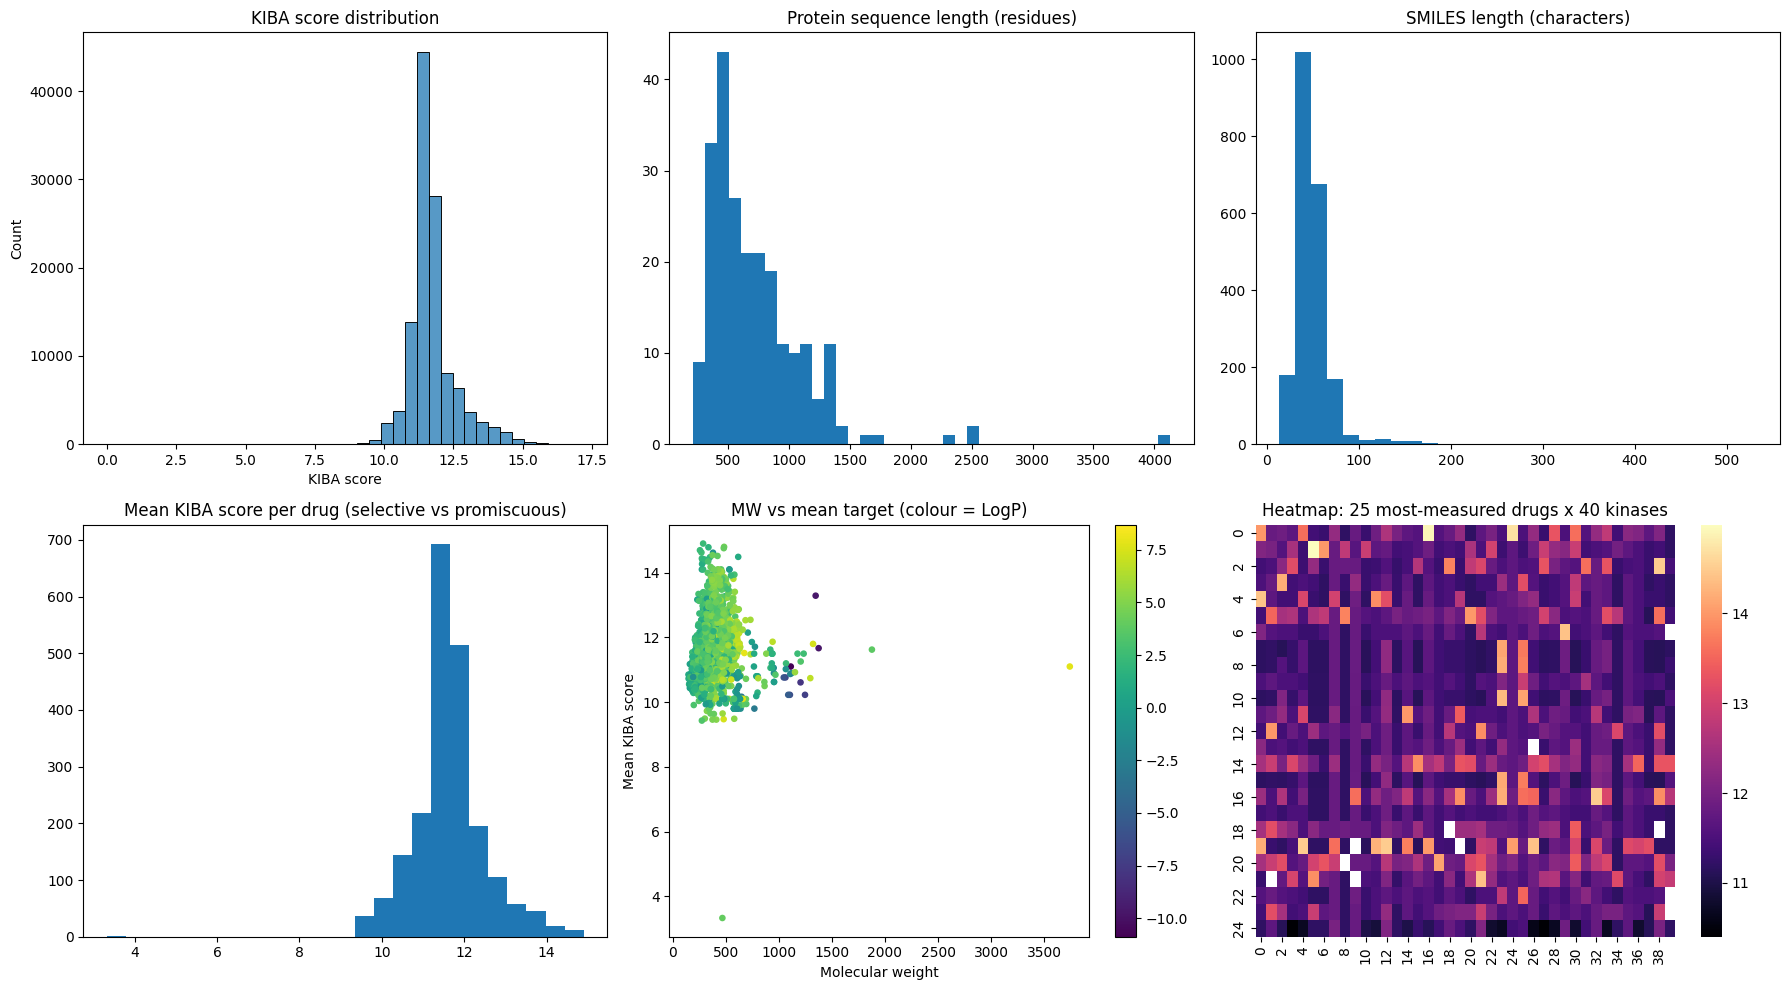

Corr(MW,   mean target): -0.039
Corr(LogP, mean target): 0.205
Most potent drugs on average : ['CHEMBL520144', 'CHEMBL162621', 'CHEMBL483525']
Least potent drugs on average: ['CHEMBL373751', 'CHEMBL281470', 'CHEMBL8091']
Kinases binding most drugs   : ['Q9UBE8', 'P09769', 'Q9H0K1']
Kinases binding fewest drugs : ['Q9BWU1', 'Q16512', 'Q9HC98']


In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, Crippen
TN = CFG["target_name"]

mols = [Chem.MolFromSmiles(s) for s in smiles]
mw = np.array([Descriptors.MolWt(m) for m in mols]); lp = np.array([Crippen.MolLogP(m) for m in mols])
drug_mean = df.groupby("drug_idx").target.mean()
prot_mean = df.groupby("prot_idx").target.mean()
M = np.full(Y.shape, np.nan); M[df.drug_idx.values, df.prot_idx.values] = df.target.values
top_d = np.argsort(-np.isfinite(M).sum(1))[:25]; top_p = np.argsort(-np.isfinite(M).sum(0))[:40]

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
sns.histplot(df.target, bins=40, ax=ax[0, 0]); ax[0, 0].set_title(f"{TN} distribution"); ax[0, 0].set_xlabel(TN)
ax[0, 1].hist([len(s) for s in seqs], bins=40);    ax[0, 1].set_title("Protein sequence length (residues)")
ax[0, 2].hist([len(s) for s in smiles], bins=30);  ax[0, 2].set_title("SMILES length (characters)")
ax[1, 0].hist(drug_mean, bins=25);                 ax[1, 0].set_title(f"Mean {TN} per drug (selective vs promiscuous)")
sc = ax[1, 1].scatter(mw[drug_mean.index], drug_mean.values, c=lp[drug_mean.index], cmap="viridis", s=14)
ax[1, 1].set_xlabel("Molecular weight"); ax[1, 1].set_ylabel(f"Mean {TN}"); ax[1, 1].set_title("MW vs mean target (colour = LogP)")
plt.colorbar(sc, ax=ax[1, 1])
sns.heatmap(M[np.ix_(top_d, top_p)], ax=ax[1, 2], cmap="magma"); ax[1, 2].set_title("Heatmap: 25 most-measured drugs x 40 kinases")
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=150); plt.show()

print("Corr(MW,   mean target):", np.corrcoef(mw[drug_mean.index], drug_mean.values)[0, 1].round(3))
print("Corr(LogP, mean target):", np.corrcoef(lp[drug_mean.index], drug_mean.values)[0, 1].round(3))
print("Most potent drugs on average :", [drug_ids[i] for i in drug_mean.sort_values(ascending=False).index[:3]])
print("Least potent drugs on average:", [drug_ids[i] for i in drug_mean.sort_values().index[:3]])
print("Kinases binding most drugs   :", [prot_ids[i] for i in prot_mean.sort_values(ascending=False).index[:3]])
print("Kinases binding fewest drugs :", [prot_ids[i] for i in prot_mean.sort_values().index[:3]])

### 4.2 Looking at actual molecules and the relationship between drug and protein effects
**What:** (a) draws six example molecules with RDKit, so the SMILES strings become real structures in the report; (b) measures **how much of the variance in the target is explained by the drug alone, by the protein alone, and by both additively**.

**Why (b) matters:** if "drug identity" already explains a large share of the variance, then a model can look good on a **random split** just by memorizing each drug's average potency, because the same drug appears in the training and test sets. The *cold-drug* split removes that shortcut. This single number motivates our two-split evaluation.

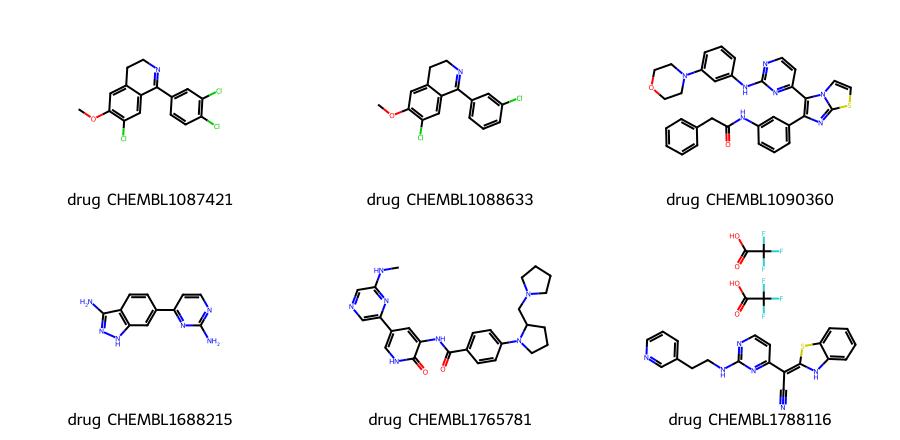

Variance explained by drug identity alone    : 42.0%
Variance explained by protein identity alone : 14.1%
Drug + protein effects (additive)            : 49.6%


In [ ]:
display(Draw.MolsToGridImage(mols[:6], molsPerRow=3, subImgSize=(300, 220),
                             legends=[f"drug {drug_ids[i]}" for i in range(6)]))

# share of target variance explained by simple group means
tot = df.target.var()
r2_drug = 1 - (df.target - df.groupby("drug_idx").target.transform("mean")).var() / tot
r2_prot = 1 - (df.target - df.groupby("prot_idx").target.transform("mean")).var() / tot
add = df.groupby("drug_idx").target.transform("mean") + df.groupby("prot_idx").target.transform("mean") - df.target.mean()
r2_add = 1 - (df.target - add).var() / tot
print(f"Variance explained by drug identity alone    : {r2_drug:.1%}")
print(f"Variance explained by protein identity alone : {r2_prot:.1%}")
print(f"Drug + protein effects (additive)            : {r2_add:.1%}")

# 5 · Data preprocessing, part 2: encoding, scaling, splitting

### 5.1 Encoding (turning text into numbers)
**What:** builds one feature vector per (drug, protein) pair using the functions from `features.py`. Features are computed **once per unique drug (68 / 2,111) and once per protein (442 / 229)**, then looked up for every pair. That is far faster than recomputing 118,254 times.

**Result:** matrix `X` of shape *(number of pairs, 1,451)* and target vector `y`.

*(The CNN uses a different encoding, integer tokens, which is built in §6.)*

### 5.2 Is feature scaling needed?
**Short answer: no, and here is why.** The requirement says "perform feature scaling *if required*":
- **Random Forest and XGBoost** choose split thresholds on one feature at a time. Multiplying a feature by 1,000 just moves the threshold, so the model is **invariant to feature scale**.
- **Fingerprint bits** are already 0/1; **composition features** are already fractions in [0, 1].
- The **CNN** learns embeddings from integer *tokens*, not raw magnitudes.

The 7 descriptors do have very different scales (molecular weight ≈ 400, ring count ≈ 4); the cell prints their ranges to show why scaling *would* matter for a linear model or a plain MLP, and why it doesn't for ours. If we later add an MLP, we would apply `StandardScaler` **fitted on the training set only** (to avoid leakage).

### 5.3 Quick-run subsampling
With `QUICK_RUN=True`, we randomly keep 4,000 pairs so the whole pipeline finishes in minutes.

In [ ]:
from features import drug_features, protein_features

if QUICK_RUN:
    df = df.sample(min(4000, len(df)), random_state=SEED).reset_index(drop=True)

D  = np.array([drug_features(s) for s in smiles])      # (n_drugs, 1031)
Pm = np.array([protein_features(s) for s in seqs])     # (n_prot, 420)
X  = np.hstack([D[df.drug_idx.values], Pm[df.prot_idx.values]]).astype(np.float32)
y  = df.target.values.astype(np.float32)
print("Drug features:", D.shape, "| protein features:", Pm.shape, "| pair matrix X:", X.shape, f"({X.nbytes/1e6:.0f} MB)")

names = ["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotBonds", "Rings"]
print("\nDescriptor ranges (why a linear model would need scaling; trees don't):")
print(pd.DataFrame(D[:, 1024:], columns=names).describe().loc[["min", "max"]].round(1).to_string())

Drug features: (2111, 1031) | protein features: (229, 420) | pair matrix X: (118254, 1451) (686 MB)

Descriptor ranges (why a linear model would need scaling; trees don't):
      MolWt  LogP    TPSA   HBD    HBA  RotBonds  Rings
min   150.2 -10.9     8.8   0.0    0.0       0.0    0.0
max  3740.5   8.7  1743.7  57.0  104.0      47.0   32.0


### 5.3 Train/test split: two protocols
**What:** two different 80/20 splits of the same pairs.

| Split | How | What it measures |
|---|---|---|
| **Random** | pairs shuffled at random | "Can the model fill in missing cells of the matrix?" The same drug appears in train and test (with different kinases) |
| **Cold-drug** | `GroupShuffleSplit` by **molecule**: every pair of a held-out drug goes to the test set | "Can the model predict for a **brand-new drug**?", the realistic drug-discovery question |

**Why two:** random splits look flattering because of the shortcut found in §4.2. The cold-drug split is stricter and more honest. We **report both**, and choose the final model mainly on the cold-drug result.

**Validation set:** inside the CNN's training routine, 10% of the training pairs are held out to pick the best epoch, so the test set is never used for any decision.

In [ ]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
idx = np.arange(len(df))
splits = {
    "random":    train_test_split(idx, test_size=0.2, random_state=SEED),
    "cold_drug": next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(idx, groups=df.grp.values)),
}
for k, (tr, te) in splits.items():
    g_tr, g_te = set(df.grp.values[tr]), set(df.grp.values[te])
    print(f"{k:10s} train pairs {len(tr):6d} | test pairs {len(te):6d} | train drugs {len(g_tr):5d} | test drugs {len(g_te):5d} | drugs in both: {len(g_tr & g_te)}")

random     train pairs  94603 | test pairs  23651 | train drugs  2068 | test drugs  2018 | drugs in both: 2018
cold_drug  train pairs  95061 | test pairs  23193 | train drugs  1654 | test drugs   414 | drugs in both: 0


# 6 · Models

## 6.1 Why these three models
The requirement asks for 2–4 models "appropriate for the problem". Our data is **tabular features (fingerprints + compositions) on one side and raw sequences on the other**, with a **numeric target**, so we cover both major families:

| # | Model | Family | Input | Why chosen | Weakness |
|---|---|---|---|---|---|
| 1 | **Random Forest** | Classical ML, *bagging* | 1,451 engineered features | Strong, robust baseline; needs almost no tuning; hard to overfit badly; handles sparse 0/1 fingerprints | Large model files; can't extrapolate beyond training range |
| 2 | **XGBoost** | Classical ML, *gradient boosting* | same 1,451 features | Usually the best model on tabular data; fast on GPU; regularized; small model file → easy deployment | Needs more careful hyperparameters; sensitive to leakage like all models |
| 3 | **DeepDTA-lite 1-D CNN** | Deep learning | raw SMILES + raw protein sequence tokens | Learns its own features instead of relying on hand-made ones; the architecture idea behind the DeepDTA paper | Needs lots of *distinct drugs* to learn chemistry; slower to train |

**Why not plain linear regression?** A linear model on the concatenated features is *additive*: `f = w·drug + v·protein`. It would rank the drugs in the **same order for every kinase**, so it cannot represent the *interaction* "this drug binds that kinase", which is exactly what we must model. Trees and neural networks learn feature interactions automatically.

**Why not graph networks / protein language models (like the thesis)?** Better in principle, but they need substantial GPU time and extra libraries. With one day, we pick models we can train, tune sanely, and fully explain. They are listed as future work.

## 6.2 Hyperparameter choices and reasons
We did **not** run an extensive search (time constraint). The values follow standard practice, and we state this honestly in the report.

| Model | Setting | Reason |
|---|---|---|
| RF | `n_estimators=100` | Enough trees for the averaging effect; more gives diminishing returns |
| RF | `max_depth=18`, `min_samples_leaf=5` | Stops trees from memorizing individual pairs (the overfitting you already know from single trees) and keeps the model size manageable |
| RF | `max_features=0.1` | Each split sees only 10% of features, so trees differ from one another, which makes averaging more effective, and training is faster |
| XGB | `learning_rate=0.05`, `n_estimators=600` | Small steps with many trees generalize better than few big steps (shrinkage) |
| XGB | `max_depth=8` | Deep enough to capture drug × protein interactions |
| XGB | `subsample=0.8`, `colsample_bytree=0.5` | Each tree sees 80% of rows and 50% of columns: random subsampling regularizes (like RF's randomness) |
| XGB | `tree_method="hist"`, GPU | Histogram-based split search is much faster on large data |
| CNN | embedding 64, filters 32/64/96, kernels 4/6/8 | Follows DeepDTA: increasing kernel sizes detect increasingly large substructures/motifs |
| CNN | global max-pool | Keeps each filter's strongest hit anywhere in the sequence → fixed-size vector for any length |
| CNN | dense 512→256→1, dropout 0.1 | The "basic NN" part; dropout reduces overfitting |
| CNN | Adam, lr 1e-3, batch 256, MSE loss | Standard defaults for regression; the best-validation-epoch weights are restored (early-stopping-style) |
| CNN | SMILES ≤ 100, protein ≤ 1000 tokens | DeepDTA's convention; longer inputs are truncated (a stated limitation) |

## 6.3 Evaluation metrics (and why six)
| Metric | Meaning | Why used |
|---|---|---|
| **MSE / RMSE** | Average squared / typical error, in target units | Standard regression error; RMSE is easiest to interpret. *Not comparable across datasets* (different target scales) |
| **R²** | Fraction of variance explained (1 = perfect, 0 = predicting the mean) | Scale-free quality measure |
| **Pearson r** | Linear correlation, predicted vs actual | Does the model move in the right direction? |
| **Spearman ρ** | Correlation of *rankings* | Ranking matters more than exact values in screening |
| **Concordance Index (CI)** | Over random pairs, how often the model correctly says which binds more strongly (0.5 = random, 1 = perfect) | **The standard metric in drug-target affinity papers**, because the real job is *ranking candidates* |

We treat **CI as the primary metric** and use the others to check consistency.

In [ ]:
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import pearsonr, spearmanr
from lifelines.utils import concordance_index

def evaluate(yt, yp):
    mse = mean_squared_error(yt, yp)
    return dict(MSE=mse, RMSE=mse ** 0.5, R2=r2_score(yt, yp),
                Pearson=pearsonr(yt, yp)[0], Spearman=spearmanr(yt, yp)[0],
                CI=concordance_index(yt, yp))

results, preds, xgb_models = [], {}, {}
RES_PATH = f"outputs/results_{DATASET.lower()}.csv"
def record(split, name, te, p, t0):
    preds[(split, name)] = p
    results.append(dict(split=split, model=name, **evaluate(y[te], p), secs=time.time() - t0))
    pd.DataFrame(results).round(3).to_csv(RES_PATH, index=False)      # saved after every model
    print(f"  {name:18s} done in {time.time() - t0:5.0f}s | CI={results[-1]['CI']:.3f} | R2={results[-1]['R2']:.3f}")

### 6.4 Train Random Forest and XGBoost (both splits)
**What:** for each split, train both tree models on the training pairs only, predict the test pairs, and record all six metrics.

**How they work (summary for the viva):**
- **Random Forest = bagging.** Train many deep-ish trees, each on a random bootstrap sample of the rows and a random subset of the features at each split; **average** their predictions. Each tree overfits differently; averaging cancels the noise (lower variance).
- **XGBoost = boosting.** Train trees **one after another**: each new small tree is fitted to the **errors (residuals) left by all previous trees**, and its output is added with a small weight (`learning_rate`). This steadily reduces bias. Built-in regularization on tree complexity and leaf weights guards against overfitting.

Test data is only touched for the final prediction, never for fitting or tuning.

In [ ]:
for split_name, (tr, te) in splits.items():
    print(f"\n===== {split_name} split =====")
    t = time.time()
    rf = RandomForestRegressor(n_estimators=N_RF, max_features=0.1, min_samples_leaf=5,
                               max_depth=18, n_jobs=-1, random_state=SEED).fit(X[tr], y[tr])
    record(split_name, "Random Forest", te, rf.predict(X[te]), t); del rf

    t = time.time()
    xg = xgb.XGBRegressor(n_estimators=N_XGB, learning_rate=0.05, max_depth=8, subsample=0.8,
                          colsample_bytree=0.5, tree_method="hist", device=dev, random_state=SEED).fit(X[tr], y[tr])
    xgb_models[split_name] = xg
    record(split_name, "XGBoost", te, xg.predict(X[te]), t)


===== random split =====
  Random Forest      done in   168s | CI=0.805 | R2=0.540
  XGBoost            done in    29s | CI=0.840 | R2=0.691

===== cold_drug split =====
  Random Forest      done in   169s | CI=0.787 | R2=0.473
  XGBoost            done in    28s | CI=0.783 | R2=0.502


### 6.5 Train the DeepDTA-lite 1-D CNN (both splits)
**What:** a deep-learning model that reads the **raw** sequences instead of engineered features.

**Pipeline per branch (one for the drug, one for the protein):**
1. **Tokenize:** every SMILES character / amino-acid letter → an integer; pad or truncate to a fixed length (100 / 1000).
2. **Embedding:** a trainable lookup table turning each integer into a 64-number vector (similar characters can get similar vectors).
3. **Three 1-D convolutions:** small filters slide along the sequence detecting local patterns: substructures such as rings and functional groups in SMILES, short motifs in proteins. Stacking layers lets deeper layers see larger patterns.
4. **Global max-pooling:** keeps each filter's strongest response anywhere in the sequence → one fixed-size vector per branch (96 numbers).
5. **Concatenate** drug (96) + protein (96) = 192 → **dense layers** (512 → 256 → 1) → predicted affinity. This last part is just the ordinary neural network you already know.

**Training:** the output bias is initialised to the mean target (so early epochs aren't wasted learning the offset); mini-batches of 256 pairs, MSE loss, Adam optimizer; after every epoch we measure error on a validation slice and **restore the best epoch** at the end.

**Expectation:** the CNN must learn chemistry from scratch, so with few distinct drugs it tends not to beat well-engineered fingerprints. Whether it does is an empirical result we report either way.

In [ ]:
import torch.nn as nn, torch.nn.functional as F

MAXS, MAXP = 100, 1000
smi_vocab = {c: i + 1 for i, c in enumerate(sorted(set("".join(smiles))))}
aa_vocab  = {c: i + 1 for i, c in enumerate("ACDEFGHIKLMNPQRSTVWY")}
def enc(s, vocab, Lmax):
    a = np.zeros(Lmax, dtype=np.int64)
    for i, c in enumerate(s[:Lmax]): a[i] = vocab.get(c, 0)
    return a
drugT = torch.tensor(np.stack([enc(s, smi_vocab, MAXS) for s in smiles]), device=dev)
protT = torch.tensor(np.stack([enc(s, aa_vocab, MAXP) for s in seqs]), device=dev)
di = torch.tensor(df.drug_idx.values, device=dev)
pi = torch.tensor(df.prot_idx.values, device=dev)
yT = torch.tensor(y, device=dev)

class Branch(nn.Module):
    def __init__(s, vocab, emb=64):
        super().__init__()
        s.emb = nn.Embedding(vocab + 1, emb, padding_idx=0)
        s.conv = nn.Sequential(nn.Conv1d(emb, 32, 4), nn.ReLU(),
                               nn.Conv1d(32, 64, 6), nn.ReLU(),
                               nn.Conv1d(64, 96, 8), nn.ReLU())
    def forward(s, x):
        return s.conv(s.emb(x).transpose(1, 2)).max(dim=2).values   # global max-pool

class DTACNN(nn.Module):
    def __init__(s):
        super().__init__()
        s.d, s.p = Branch(len(smi_vocab)), Branch(len(aa_vocab))
        s.head = nn.Sequential(nn.Linear(192, 512), nn.ReLU(), nn.Dropout(0.1),
                               nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.1),
                               nn.Linear(256, 1))
    def forward(s, d, p):
        return s.head(torch.cat([s.d(d), s.p(p)], 1)).squeeze(-1)

def run_cnn(tr, te, epochs, bs=256, lr=1e-3):
    torch.manual_seed(SEED)
    tr, va = train_test_split(tr, test_size=0.1, random_state=1)      # validation slice for epoch selection
    model = DTACNN().to(dev)
    model.head[-1].bias.data.fill_(float(y[tr].mean()))      # start predictions at the mean target (speeds up convergence)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    def predict(ix):
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(ix), 1024):
                b = torch.tensor(ix[i:i + 1024], device=dev)
                out.append(model(drugT[di[b]], protT[pi[b]]).cpu())
        return torch.cat(out).numpy()
    best, state = 1e9, None
    for ep in range(epochs):
        model.train()
        perm = np.random.permutation(tr)
        for i in range(0, len(perm), bs):
            b = torch.tensor(perm[i:i + bs], device=dev)
            loss = F.mse_loss(model(drugT[di[b]], protT[pi[b]]), yT[b])
            opt.zero_grad(); loss.backward(); opt.step()
        v = ((predict(va) - y[va]) ** 2).mean()
        if v < best: best, state = v, {k: t.clone() for k, t in model.state_dict().items()}
        if ep % 5 == 0 or ep == epochs - 1: print(f"    epoch {ep:2d} | val MSE {v:.4f}")
    model.load_state_dict(state)
    return predict(te)

for split_name, (tr, te) in splits.items():
    print(f"\n===== CNN | {split_name} split =====")
    t = time.time()
    record(split_name, "DeepDTA-lite CNN", te, run_cnn(tr, te, CFG["cnn_epochs"]), t)


===== CNN | random split =====
    epoch  0 | val MSE 0.4180
    epoch  5 | val MSE 0.2699
    epoch 10 | val MSE 0.2328
    epoch 15 | val MSE 0.2183
    epoch 20 | val MSE 0.2026
    epoch 24 | val MSE 0.1943
  DeepDTA-lite CNN   done in   483s | CI=0.854 | R2=0.716

===== CNN | cold_drug split =====
    epoch  0 | val MSE 0.3699
    epoch  5 | val MSE 0.2627
    epoch 10 | val MSE 0.2094
    epoch 15 | val MSE 0.1829
    epoch 20 | val MSE 0.1772
    epoch 24 | val MSE 0.1749
  DeepDTA-lite CNN   done in   476s | CI=0.760 | R2=0.419


# 7 · Model comparison and selection

### 7.1 Results table, bar chart, automatic best-model pick
**What:** gathers all results into one table, plots the primary metric (CI) per model and split, and prints the best model per split.

**How to choose the final model (our rule, stated up front):**
1. **Primary criterion: CI on the cold-drug split**, because the real use of the system is scoring *new* molecules.
2. The random-split result is reported as secondary context (it measures filling gaps in a known drug set).
3. If models are within noise of each other, **break ties by practicality**: training time, model size, ease of deployment and explanation.

,split,model,MSE,RMSE,R2,Pearson,Spearman,CI,secs
0,cold_drug,Random Forest,0.382,0.618,0.473,0.699,0.716,0.787,168.541
1,cold_drug,XGBoost,0.360,0.600,0.502,0.710,0.708,0.783,28.176
2,cold_drug,DeepDTA-lite CNN,0.421,0.649,0.419,0.657,0.656,0.760,475.744
3,random,DeepDTA-lite CNN,0.199,0.446,0.716,0.849,0.839,0.854,483.056
4,random,XGBoost,0.216,0.465,0.691,0.836,0.822,0.840,29.257
5,random,Random Forest,0.322,0.568,0.540,0.751,0.756,0.805,167.670


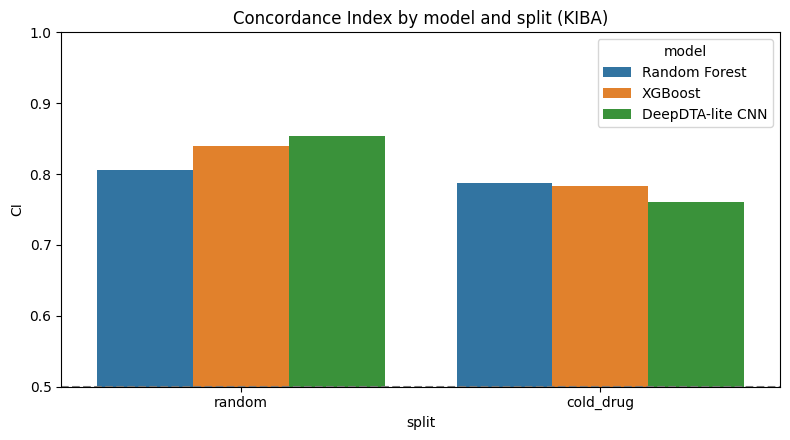


Best on random    : DeepDTA-lite CNN   CI=0.854  R2=0.716  MSE=0.199  train+predict=483s
Best on cold_drug : Random Forest      CI=0.787  R2=0.473  MSE=0.382  train+predict=169s


In [ ]:
res = pd.DataFrame(results).round(3)
display(res.sort_values(["split", "CI"], ascending=[True, False]).reset_index(drop=True))

plt.figure(figsize=(8, 4.5))
sns.barplot(data=res, x="split", y="CI", hue="model"); plt.ylim(0.5, 1.0); plt.axhline(0.5, ls="--", c="grey")
plt.title(f"Concordance Index by model and split ({DATASET})"); plt.tight_layout()
plt.savefig("figures/ci_comparison.png", dpi=150); plt.show()

print()
for sn in splits:
    b = res[res.split == sn].sort_values("CI", ascending=False).iloc[0]
    print(f"Best on {sn:10s}: {b.model:18s} CI={b.CI}  R2={b.R2}  MSE={b.MSE}  train+predict={b.secs:.0f}s")

### 7.2 Predicted vs. actual scatter plots
**What:** one plot per model and split. The dashed diagonal is a perfect prediction.

**How to read them:** a tight cloud along the diagonal = accurate. A cloud that is **wide or flat** (like a horizontal band) means the model mostly predicts the average, which is what we expect on the cold-drug split. On DAVIS, expect a dense band at pKd = 5 (the floor effect found in §4).

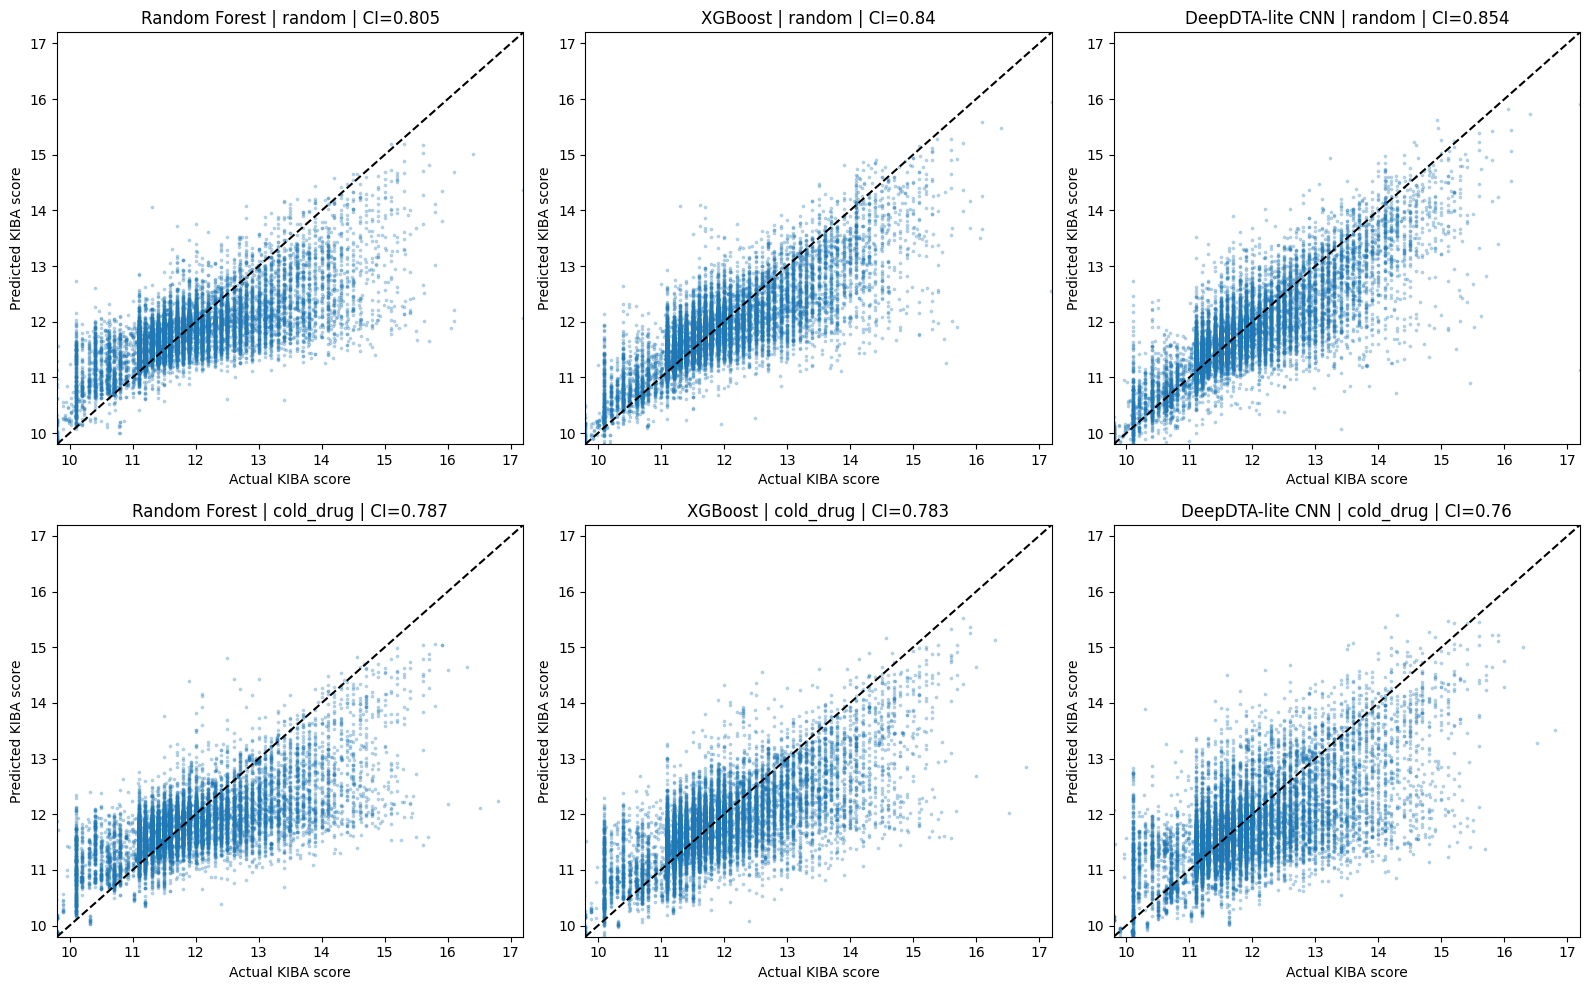

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
lim = [np.percentile(y, 0.5), y.max()]
for r, sn in enumerate(splits):
    te = splits[sn][1]
    for c, m in enumerate(["Random Forest", "XGBoost", "DeepDTA-lite CNN"]):
        a = ax[r, c]; a.scatter(y[te], preds[(sn, m)], s=3, alpha=0.25); a.plot(lim, lim, "k--")
        a.set_xlim(lim); a.set_ylim(lim)
        ci = res[(res.split == sn) & (res.model == m)].CI.values[0]
        a.set_title(f"{m} | {sn} | CI={ci}"); a.set_xlabel(f"Actual {TN}"); a.set_ylabel(f"Predicted {TN}")
plt.tight_layout(); plt.savefig("figures/pred_vs_actual.png", dpi=150); plt.show()

### 7.3 Reference: results from our earlier DAVIS run
For context, here are the numbers we obtained on **DAVIS** (68 drugs) in the first run. Your re-run should land close to these but is not guaranteed to be identical (random seeds, GPU non-determinism).

| Split | Model | MSE | R² | Pearson | CI |
|---|---|---|---|---|---|
| random | Random Forest | 0.338 | 0.552 | 0.748 | 0.855 |
| random | **XGBoost** | **0.273** | **0.638** | **0.799** | **0.876** |
| random | CNN | 0.332 | 0.560 | 0.752 | 0.854 |
| cold-drug | Random Forest | 0.659 | 0.097 | 0.337 | 0.659 |
| cold-drug | XGBoost | 0.697 | 0.044 | 0.322 | 0.663 |
| cold-drug | CNN | 0.657 | 0.099 | 0.364 | 0.665 |

**Reading:** on the random split XGBoost clearly wins. On the cold-drug split **all models collapse to CI ≈ 0.66 and are indistinguishable**. With only 68 drugs (≈ 14 in the test set) the estimate is noisy, and 54 training drugs are not enough chemical diversity to generalize. This is exactly why we move to KIBA (§7.4 quantifies it with a learning curve).

### 7.4 How XGBoost works (the model we expect to deploy)
*Read this even if another model wins on your run: tree boosting is the core idea.*

**Prediction:** the model is a *sum* of small regression trees,

$$\hat y(x) \;=\; \sum_{k=1}^{K} \eta \, f_k(x)$$

where each $f_k$ is a tree (a set of yes/no questions on features ending in a number) and $\eta$ is the **learning rate** (0.05).

**Training, step by step:**
1. Start with a constant guess (e.g., the mean target).
2. Compute the **residuals** $r_i = y_i - \hat y_i$ (for squared-error loss, residuals are the negative gradient of the loss).
3. Fit a **small tree** to predict those residuals, i.e., learn where the current model is wrong.
4. Add $\eta \times$ (that tree) to the prediction. Repeat for $K = 600$ rounds.

This is **gradient descent in function space**: where a neural network nudges *weights* downhill, boosting adds *trees* downhill.

**Regularized objective** (what XGBoost adds over plain gradient boosting):

$$\mathcal{L} = \sum_i \ell(y_i, \hat y_i) + \sum_k \Big( \gamma\, T_k + \tfrac{1}{2}\lambda \lVert w_k \rVert^2 \Big)$$

It penalizes the number of leaves $T_k$ and large leaf values $w_k$, uses second-order (curvature) information to choose splits, handles sparse 0/1 inputs efficiently, and uses histogram-based split finding (fast on GPU).

**Why it suits our data:** fingerprints are sparse binary features; trees need no scaling; depth-8 trees can represent *interactions* between a drug substructure and a protein composition feature, which is what binding depends on; and the saved model is only a few MB.

**Compared with Random Forest:** RF trains deep trees *in parallel* and **averages** (reduces variance); XGBoost trains shallow trees *sequentially* to **correct errors** (reduces bias). **Compared with the CNN:** XGBoost relies on our engineered features, while the CNN learns its own but needs many more distinct drugs to do it well.

### 7.5 Learning curve: how many training drugs are enough?
**What:** with the **same fixed cold-drug test set**, train XGBoost on 10, 20, … up to hundreds of *training drugs* (3 random draws per size) and plot test CI against the number of drugs.

**Why:** it answers "how many drugs do we need?" with evidence, and also tells us whether the problem is **data quantity** (curve still rising at the right end → more drugs would help) or **feature/model limits** (curve flat → more drugs won't help). It also explains the DAVIS result: ~54 drugs sit on the steep early part of the curve.

*(Uses smaller, faster XGBoost settings: 300 trees at learning rate 0.1. The curve is about the trend, not the absolute number.)*

training drugs available: 1654 | test drugs: 414
     50 drugs -> mean CI 0.662
    100 drugs -> mean CI 0.679
    200 drugs -> mean CI 0.708
    400 drugs -> mean CI 0.724
    800 drugs -> mean CI 0.751
   1600 drugs -> mean CI 0.775


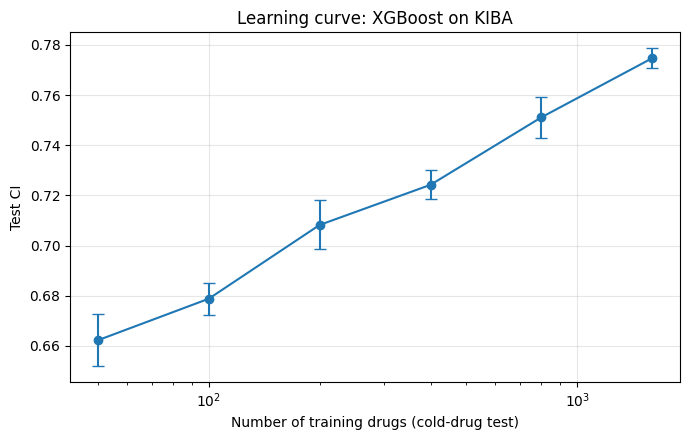

In [ ]:
tr, te = splits["cold_drug"]
tr_groups = np.unique(df.grp.values[tr])
print("training drugs available:", len(tr_groups), "| test drugs:", len(set(df.grp.values[te])))

lc = []
for n in CFG["lc_sizes"]:
    if n > len(tr_groups): continue
    for seed in range(3):
        g = np.random.RandomState(seed).choice(tr_groups, n, replace=False)
        sub = tr[np.isin(df.grp.values[tr], g)]
        m = xgb.XGBRegressor(n_estimators=N_LC, learning_rate=0.1, max_depth=8, subsample=0.8,
                             colsample_bytree=0.5, tree_method="hist", device=dev, random_state=seed).fit(X[sub], y[sub])
        p = m.predict(X[te])
        lc.append(dict(n_drugs=n, seed=seed, CI=concordance_index(y[te], p), MSE=mean_squared_error(y[te], p)))
    print(f"  {n:5d} drugs -> mean CI {np.mean([r['CI'] for r in lc if r['n_drugs'] == n]):.3f}")

lcdf = pd.DataFrame(lc); lcdf.to_csv(f"outputs/learning_curve_{DATASET.lower()}.csv", index=False)
g = lcdf.groupby("n_drugs").CI.agg(["mean", "std"]).reset_index()
plt.figure(figsize=(7, 4.5))
plt.errorbar(g.n_drugs, g["mean"], yerr=g["std"], marker="o", capsize=4)
plt.xscale("log"); plt.xlabel("Number of training drugs (cold-drug test)"); plt.ylabel("Test CI")
plt.title(f"Learning curve: XGBoost on {DATASET}"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("figures/learning_curve.png", dpi=150); plt.show()

### 7.6 What did XGBoost actually learn? (feature importance)
**What:** XGBoost reports how much each feature contributed to its splits (**gain-based importance**). We sum it by feature *group* and list the top individual features, using the cold-drug-split model.

**Why:** the requirement says understanding of the selected model is a must. This shows **whether the model relies on drug features, protein features, or both**, which is also a sanity check:
- If importance is overwhelmingly on drug features, the model mostly learned "which drugs are potent in general" (the shortcut from §4.2).
- Substantial protein importance means it uses kinase-specific information.

*Importance shows what the model **uses**, not biological causation.*

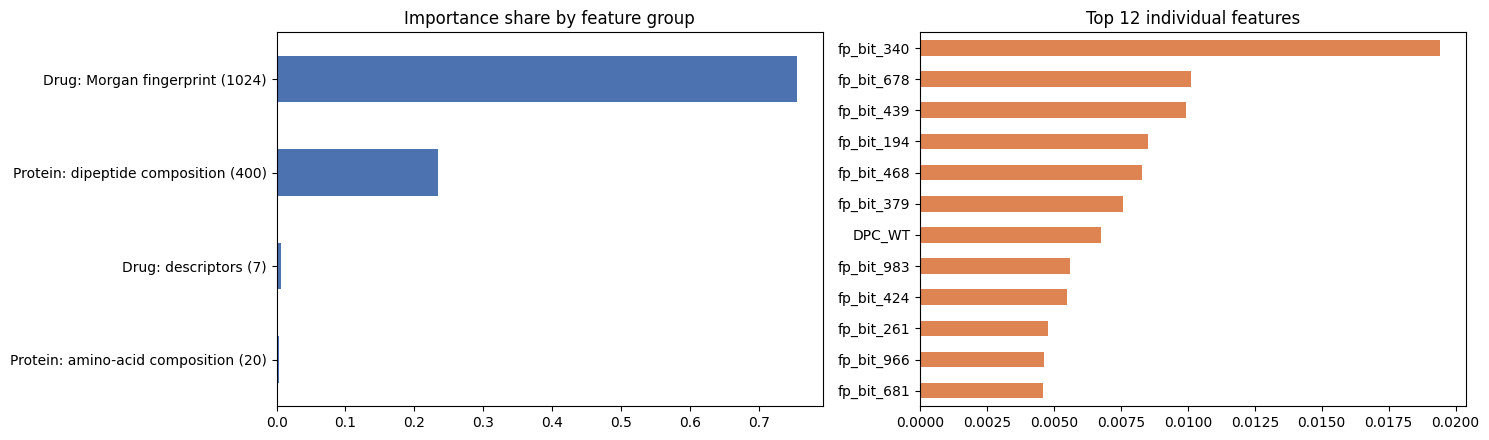

Drug: Morgan fingerprint (1024)         75.5 %
Drug: descriptors (7)                    0.6 %
Protein: amino-acid composition (20)     0.4 %
Protein: dipeptide composition (400)    23.5 %
dtype: object


In [ ]:
imp = xgb_models["cold_drug"].feature_importances_
aa = "ACDEFGHIKLMNPQRSTVWY"
fnames = [f"fp_bit_{i}" for i in range(1024)] + names + [f"AAC_{a}" for a in aa] + [f"DPC_{a}{b}" for a in aa for b in aa]
assert len(fnames) == X.shape[1] == len(imp)

groups = {"Drug: Morgan fingerprint (1024)": imp[:1024], "Drug: descriptors (7)": imp[1024:1031],
          "Protein: amino-acid composition (20)": imp[1031:1051], "Protein: dipeptide composition (400)": imp[1051:]}
gsum = pd.Series({k: v.sum() for k, v in groups.items()}); gsum = gsum / gsum.sum()
top = pd.Series(imp, index=fnames).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
gsum.sort_values().plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Importance share by feature group")
top[::-1].plot.barh(ax=ax[1], color="#dd8452"); ax[1].set_title("Top 12 individual features")
plt.tight_layout(); plt.savefig("figures/feature_importance.png", dpi=150); plt.show()
print((gsum * 100).round(1).astype(str) + " %")

### 7.7 Automatic summary
Prints the selection per our rule (cold-drug CI first, then random-split CI). **Use this text as the starting point of your "best model" paragraph**, and add the *why* from §7.4 and the learning curve / importance plots.

In [ ]:
cold = res[res.split == "cold_drug"].sort_values("CI", ascending=False)
rand = res[res.split == "random"].sort_values("CI", ascending=False)
best_cold, best_rand = cold.iloc[0], rand.iloc[0]
spread = cold.CI.max() - cold.CI.min()
print(f"Dataset: {DATASET} | pairs: {len(df)} | drugs: {df.grp.nunique()} | kinases: {df.prot_idx.nunique()}")
print(f"Best on RANDOM split   : {best_rand.model} (CI {best_rand.CI})")
print(f"Best on COLD-DRUG split: {best_cold.model} (CI {best_cold.CI}); spread between models = {spread:.3f}")
if spread < 0.01:
    print("-> Cold-drug differences are tiny (<0.01 CI): treat the models as tied and choose on practicality (speed, size, explainability).")
else:
    print("-> Cold-drug differences are meaningful: prefer the best cold-drug model.")
print("\nTimings (s):"); print(res.pivot(index="model", columns="split", values="secs").round(0))

Dataset: KIBA | pairs: 118254 | drugs: 2068 | kinases: 229
Best on RANDOM split   : DeepDTA-lite CNN (CI 0.854)
Best on COLD-DRUG split: Random Forest (CI 0.787); spread between models = 0.027
-> Cold-drug differences are meaningful: prefer the best cold-drug model.

Timings (s):
split             cold_drug  random
model                              
DeepDTA-lite CNN      476.0   483.0
Random Forest         169.0   168.0
XGBoost                28.0    29.0


# 8 · Deployment: export the model and demo the prediction path

### 8.1 Train the deployment model on all data
**What:** retrains XGBoost on **all** pairs (train + test) and saves it to the repository root — `model.json`, `kinases.csv`, `meta.json` — alongside `features.py` (already written in §1.3). The submitted web workbench (`app.py` + `index.html`) loads exactly these files.

**Why retrain on everything:** more data → slightly better final model. The **reported metrics still come from the held-out test splits above**, never from this model (say so in the report).

**Why XGBoost:** a single ~10 MB file, millisecond predictions on a CPU, and it only needs `features.py` — ideal for the local app.

**Important caveat shown in the app:** predictions for drugs *outside* the training set are much less reliable than the random-split numbers suggest (see cold-drug CI).


In [ ]:
# Retrain on all data and export the artefacts the web app loads (repository root).
final = xgb.XGBRegressor(n_estimators=N_XGB, learning_rate=0.05, max_depth=8, subsample=0.8,
                         colsample_bytree=0.5, tree_method="hist", device=dev, random_state=SEED).fit(X, y)
final.save_model("model.json")
pd.DataFrame({"gene": prot_ids, "sequence": seqs}).to_csv("kinases.csv", index=False)
pd.DataFrame({"cid": drug_ids, "smiles": smiles}).to_csv("outputs/drugs.csv", index=False)

xg_cold = res[(res.split == "cold_drug") & (res.model == "XGBoost")]
meta = dict(dataset=DATASET, target_name=CFG["target_name"], is_pkd=CFG["is_pkd"],
            strong=CFG["strong"], moderate=CFG["moderate"],
            n_drugs=int(df.grp.nunique()), n_kinases=int(df.prot_idx.nunique()),
            cold_ci=float(xg_cold.CI.iloc[0]) if len(xg_cold) else None,
            random_ci=float(res[(res.split == "random") & (res.model == "XGBoost")].CI.iloc[0]))
json.dump(meta, open("meta.json", "w"), indent=2)
print(meta); print("model size: %.1f MB" % (os.path.getsize("model.json") / 1e6))
print("Web app loads: model.json, kinases.csv, meta.json, features.py")


{'dataset': 'KIBA', 'target_name': 'KIBA score', 'is_pkd': False, 'strong': 12.1, 'moderate': 11.5, 'n_drugs': 2068, 'n_kinases': 229, 'cold_ci': 0.783, 'random_ci': 0.84}
model size: 10.5 MB


### 8.2 Demo of the same prediction path inside the notebook
**What:** calls the trained model exactly as the web app would (SMILES + kinase → features → prediction).

**Why:** a quick check that the full input → output path works before deploying, and a reproducible example for the report. The example uses imatinib, an approved kinase inhibitor, against a few kinases.


In [ ]:
from features import pair_features
def predict_affinity(smi, kinase_id):
    seq = seqs[prot_ids.index(kinase_id)]
    return float(final.predict(pair_features(canon(smi), seq))[0])

imatinib = "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1"
rows_out = []
for k in prot_ids[:5]:
    s = predict_affinity(imatinib, k)
    rows_out.append({"kinase": k, f"predicted {TN}": round(s, 2),
                     **({"Kd (nM)": round(10 ** (9 - s))} if CFG["is_pkd"] else {}),
                     "class": "strong" if s >= CFG["strong"] else "moderate" if s >= CFG["moderate"] else "weak"})
display(pd.DataFrame(rows_out))

,kinase,predicted KIBA score,class
0,O00141,11.79,moderate
1,O00311,12.22,strong
2,O00329,12.18,strong
3,O00418,11.74,moderate
4,O00444,12.07,moderate


# 9 · Final Results, Conclusion, Limitations and Future Work

## 9.1 Summary of the project
We built a machine-learning system that predicts how strongly a **drug molecule (SMILES)** binds to a **kinase protein (amino-acid sequence)**. We trained on the public **KIBA** benchmark (118,254 measured drug–kinase pairs, 2,068 unique drugs, 229 kinases) and compared three models: **Random Forest**, **XGBoost** and a **DeepDTA-style 1-D CNN**. Each was evaluated on two test protocols, a **random split** and a stricter **cold-drug split** (test drugs never seen in training, 414 held-out drugs). The best model was deployed as an interactive, monochrome **Three.js web workbench** (`app.py` + `index.html`), which renders the predicted 3D conformer, the target kinase's 3D backbone (AlphaFold), and the model's evaluation charts.

## 9.2 Final results (KIBA, held-out test sets)

| Split | Model | MSE ↓ | R² ↑ | Pearson ↑ | Spearman ↑ | **CI ↑** | Train time |
|---|---|---|---|---|---|---|---|
| Random | Random Forest | 0.322 | 0.540 | 0.751 | 0.756 | 0.805 | 168 s |
| Random | XGBoost | 0.216 | 0.691 | 0.836 | 0.822 | 0.840 | 29 s |
| Random | CNN | **0.199** | **0.716** | **0.849** | **0.839** | **0.854** | 483 s |
| Cold-drug | Random Forest | 0.382 | 0.473 | 0.699 | 0.716 | **0.787** | 169 s |
| Cold-drug | **XGBoost** | **0.360** | **0.502** | **0.710** | 0.708 | 0.783 | **28 s** |
| Cold-drug | CNN | 0.421 | 0.419 | 0.657 | 0.656 | 0.760 | 476 s |

*CI = Concordance Index (0.5 = random ranking, 1.0 = perfect), our primary metric because the real task is ranking candidate drugs. Data: 94,603 / 23,651 train/test pairs (random split); 95,061 / 23,193 pairs with 1,654 train drugs and 414 test drugs and zero overlap (cold-drug split).*

## 9.3 Key findings

1. **Random-split scores overstate real performance.** Drug identity alone explains **42.0%** of the variance in KIBA scores (protein identity alone: 14.1%; both additively: 49.6%). A model can score well simply by recognising a drug it saw in training. This is why we report the cold-drug split, the realistic test for new molecules.
2. **The CNN wins the random split but loses on unseen drugs** (CI 0.854 vs 0.840 for XGBoost on random; 0.760 vs 0.783 on cold-drug). The most likely explanation is that it exploits drug identity more strongly than the tree models, which does not transfer to new molecules. It also took about 16× longer to train than XGBoost.
3. **Random Forest and XGBoost are effectively tied on cold-drug CI** (0.787 vs 0.783, a gap of 0.004). XGBoost is better on MSE, R² and Pearson in that split.
4. **More training drugs help steadily, with no plateau.** In the learning curve (cold-drug split, XGBoost), CI rose from **0.662 (50 drugs)** to 0.679 (100), 0.708 (200), 0.724 (400), 0.751 (800) and **0.775 (1,600)**, roughly +0.02–0.03 per doubling. The 50-drug result matches the ≈0.66 cold-drug CI we obtained earlier on DAVIS (54 training drugs), supporting the explanation that DAVIS was limited by the number of drugs. (The datasets differ, so this is supporting evidence, not proof.)
5. **XGBoost uses both sides of the interaction.** About **75%** of its feature importance is on drug fingerprint bits, about **24%** on protein dipeptide composition, and about 1% on the molecular descriptors and amino-acid composition combined.

## 9.4 Selected model: XGBoost
**Selection rule (fixed before looking at results):** choose by cold-drug CI; if models are within about 0.01 CI, treat them as tied and break the tie on practicality (speed, size, deployability, explainability).

**Outcome:** the cold-drug CIs of Random Forest (0.787) and XGBoost (0.783) are effectively tied, so XGBoost was chosen because it:
- matches RF on ranking quality and is **better on MSE (0.360 vs 0.382), R² (0.502 vs 0.473) and Pearson (0.710 vs 0.699)** on unseen drugs;
- trains **~6× faster than RF and ~16× faster than the CNN** (28 s vs 169 s vs 476 s);
- produces a **10.5 MB** model file that loads and predicts in milliseconds on a free CPU server;
- is well suited to our data: sparse 0/1 fingerprint features, no scaling needed, and depth-8 trees can represent drug × protein interactions.

**How it works (short version):** XGBoost builds a sum of small decision trees, ŷ(x) = Σ η·f_k(x). Each new tree is fitted to the **residual errors** of all previous trees and added with a small learning rate (η = 0.05), a form of gradient descent in function space. Built-in regularization (penalties on tree size and leaf values) plus row and column subsampling control overfitting. Random Forest instead averages many independent deep trees to reduce variance, and the CNN learns its own features from raw sequences but needs many more distinct drugs to do so well.

## 9.5 Conclusion
We compared Random Forest, XGBoost and a DeepDTA-style 1-D CNN for kinase–drug binding-affinity prediction on the KIBA benchmark. On a random split all models perform well (CI 0.81–0.85), but this is partly because the same drugs appear in training and test data. On the stricter **cold-drug split**, which mimics screening new compounds, performance drops to **CI 0.76–0.79**, and the tree-based models outperform the CNN. **XGBoost** was selected as the final model: it ties Random Forest on ranking quality (CI 0.783), has the best error metrics on unseen drugs (MSE 0.360, R² 0.502), and is by far the most practical to train and deploy. The learning curve shows that accuracy on new drugs keeps improving as more training drugs are added, so the main limit is data diversity rather than the model. The final model is deployed as a local web workbench where a user enters a SMILES string and chooses (or pastes) a kinase sequence, and receives a predicted KIBA score, a binder class, an interactive 3D conformer of the molecule, and a 3D backbone of the target kinase.

## 9.6 Limitations (stated honestly)
- **Moderate cold-drug accuracy.** A cold-drug CI of ≈ 0.78 means the model is useful for *ranking and prioritising* candidates, not for exact potency prediction.
- **Random vs. cold-drug gap.** Random-split numbers should not be quoted as the expected performance on new molecules.
- **RF vs. XGBoost is a near-tie.** The 0.004 CI gap is within what we would expect from noise; we ran a single seed and split and report no confidence intervals.
- **Kinases only.** KIBA and DAVIS contain kinase targets; the model should not be trusted for other protein families.
- **Simple protein representation.** Composition features lose long-range sequence order and ignore 3-D structure. The CNN truncates SMILES at 100 characters and proteins at 1,000 residues (some kinases reach about 4,100 residues).
- **KIBA is a composite score**, not a physical quantity, so there is no Kd conversion in the app; MSE is not comparable with DAVIS. The app's binder classes are thresholds: 12.1 is the standard "strong" cutoff, and "weak" simply means below the dataset median (11.5).
- **Limited tuning.** Hyperparameters follow standard practice, with no grid search (one-day timeline). The CNN was trained for 25 epochs.
- **Fingerprint bits are hashed**, so an important bit cannot be mapped to one specific chemical substructure with certainty.
- **Deployed model is trained on all data**, so predictions for drugs in KIBA are in-sample. All reported metrics come from held-out splits only.
- **Not validated experimentally.** Predictions are computational estimates and not a substitute for lab assays.

## 9.7 Future work
- Add more drugs and target families (**BindingDB, ChEMBL**), since the learning curve shows data diversity is the main limiting factor.
- Replace composition features with **protein language-model embeddings (ESM-2)** and fingerprints with a **graph neural network** on the molecular graph (the direction taken in the DeepPharmaGen thesis that inspired this work).
- Run proper **hyperparameter search (Optuna)**, multiple seeds, and report confidence intervals; try an **XGBoost + CNN ensemble**.
- Add **uncertainty estimates** so the app can report how confident each prediction is.
- Extend to **target-conditioned molecule generation**, the second half of the thesis.

## 9.8 Submission checklist

| Item | Link / location |
|---|---|
| Source code (GitHub) | https://github.com/p243000/tinypharmagen |
| Web app | Local demo: `python app.py` -> http://127.0.0.1:8000 (open `/?demo=1` for an automatic prediction) |
| Demo video | Run the app and record the flow SMILES -> kinase -> prediction -> 3D conformer |
| Dataset | https://github.com/hkmztrk/DeepDTA/tree/master/data (KIBA) |
| Project report | `report/project_report.pdf` |
| Team members | Vinod Kumar (24P3012), Pir Ahmed Shah (24P3000), Muhammad Maaz (24P3032) |

**References:** Davis et al., *Nat. Biotechnol.* 2011 · Tang et al., *J. Chem. Inf. Model.* 2014 (KIBA) · Öztürk et al., *Bioinformatics* 2018 (DeepDTA) · Breiman, *Machine Learning* 2001 (Random Forest) · Chen & Guestrin, KDD 2016 (XGBoost) · Rogers & Hahn, *J. Chem. Inf. Model.* 2010 (Morgan/ECFP fingerprints) · RDKit open-source cheminformatics toolkit · P. R. Shah, *DeepPharmaGen*, final-year project report, AWKUM, 2026 (inspiration).